# 👗 ModaVision AI — Automação Inteligente de Catálogo para E-commerce de Moda
**Atividade Prática 4 — NeuroStartup (Disciplina: Inteligência Artificial e Machine Learning)**

### 👥 Integrantes do Grupo
- **Allan Reis da Conceição** — RA: 1539160
- **Gabriel Noriler Souza** — RA: 1642714
- **Mayara Franciele Santos da Silva** — RA: 1873454

---

## 📌 Passo 1 — Conhecer os Dados e a Regra do Cofre

### 🏢 Contexto de Negócio: O Problema e o Cliente da ModaVision AI
- **O Problema:** Grandes marketplaces e plataformas de e-commerce de moda (como **Mercado Livre, Shein, Shopee e Dafiti**) recebem diariamente dezenas de milhares de novos anúncios cadastrados por vendedores terceiros (sellers). O preenchimento manual da categoria de cada peça de vestuário é lento, custoso e sujeito a erros humanos (por exemplo, cadastrar uma *camisa social* como *camiseta*, ou uma *bota* como *tênis*). Produtos em categorias erradas prejudicam os filtros de busca, reduzem a taxa de conversão de vendas e aumentam os custos de moderação manual.
- **Quem é o nosso Cliente:** Diretores de Operações e Catalogação de **Marketplaces e E-commerces de Moda**, bem como grandes lojistas que desejam automatizar a triagem e categorização instantânea de peças a partir da foto enviada no cadastro do produto.
- **Nossa Solução:** A **ModaVision AI** desenvolveu um motor de Visão Computacional baseado em Redes Neurais que classifica automaticamente a foto da peça de roupa em **10 categorias padronizadas**, acelerando o onboarding de produtos e reduzindo drasticamente os erros de catalogação.

In [1]:
# Configuração inicial, importação de bibliotecas e semente de reprodutibilidade (SEED = 42)
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import ipywidgets as widgets
from IPython.display import display

# Fixando a semente aleatória conforme exigido (SEED = 42)
SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

# Configuração visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110

print(f'TensorFlow / Keras versão: {tf.__version__}')
print(f'Semente aleatória fixada em SEED = {SEED}')

TensorFlow / Keras versão: 2.21.0
Semente aleatória fixada em SEED = 42


In [2]:
# Carregamento do dataset Fashion MNIST diretamente do Keras
(X_dev_raw, y_dev_raw), (X_teste_raw, y_teste) = keras.datasets.fashion_mnist.load_data()

# Mapeamento oficial das 10 classes em português
NOMES_CLASSES = [
    'Camiseta/Top',  # 0
    'Calça',         # 1
    'Suéter',        # 2
    'Vestido',       # 3
    'Casaco',        # 4
    'Sandália',      # 5
    'Camisa',        # 6
    'Tênis',         # 7
    'Bolsa',         # 8
    'Bota'           # 9
]

print('=== Resumo Bruto do Dataset Fashion MNIST ===')
print(f'Conjunto original de desenvolvimento: {X_dev_raw.shape} imagens | Rótulos: {y_dev_raw.shape}')
print(f'Conjunto oficial de teste (COFRE):    {X_teste_raw.shape} imagens | Rótulos: {y_teste.shape}')
print(f'Escala original dos pixels: min = {X_dev_raw.min()}, max = {X_dev_raw.max()}')

=== Resumo Bruto do Dataset Fashion MNIST ===
Conjunto original de desenvolvimento: (60000, 28, 28) imagens | Rótulos: (60000,)
Conjunto oficial de teste (COFRE):    (10000, 28, 28) imagens | Rótulos: (10000,)
Escala original dos pixels: min = 0, max = 255


### 📊 Gráfico Exploratório 1: Amostras Reais das 10 Categorias do Catálogo

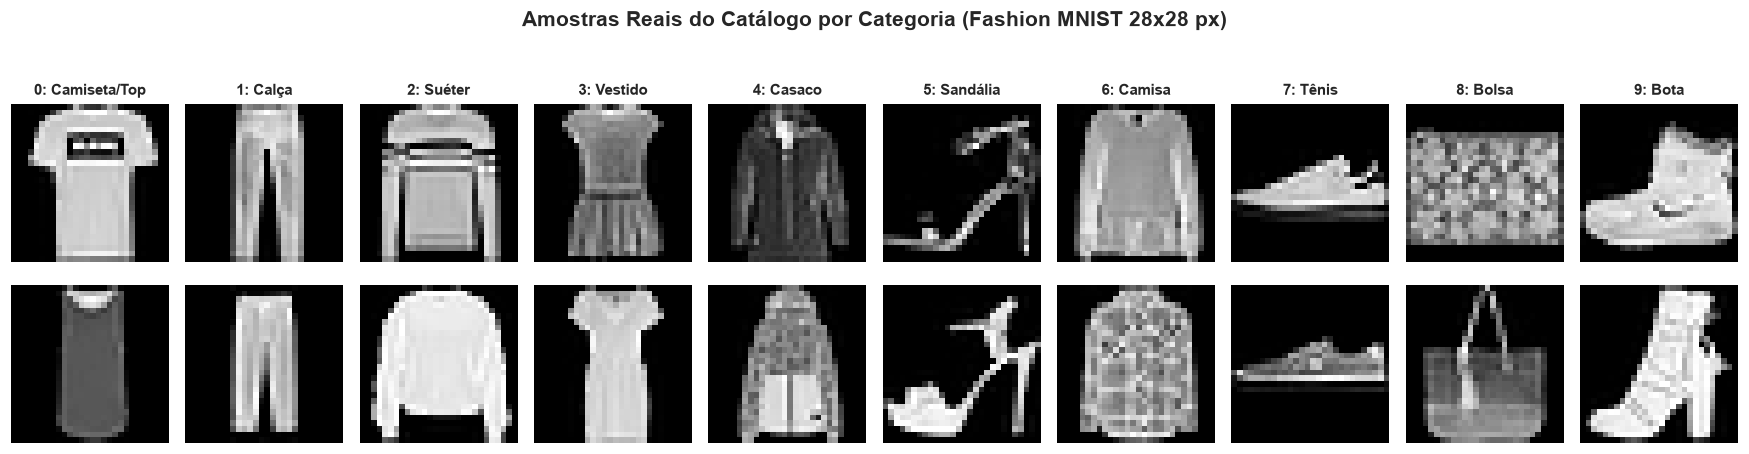

Conclusão do Gráfico 1: As imagens possuem baixa resolução (28x28 pixels em tons de cinza) e peças de tronco superior (Camiseta/Top, Suéter, Casaco e Camisa) apresentam silhuetas visualmente muito parecidas, o que exige modelos capazes de capturar detalhes espaciais finos.


In [3]:
# Gráfico Exploratório 1: Grade 2x5 exibindo 2 exemplos reais de cada uma das 10 categorias
fig, axes = plt.subplots(2, 10, figsize=(16, 4.2))
fig.suptitle('Amostras Reais do Catálogo por Categoria (Fashion MNIST 28x28 px)', fontsize=14, fontweight='bold', y=1.03)

for classe_id in range(10):
    indices_classe = np.where(y_dev_raw == classe_id)[0]
    for linha in range(2):
        ax = axes[linha, classe_id]
        img = X_dev_raw[indices_classe[linha]]
        ax.imshow(img, cmap='gray')
        ax.axis('off')
        if linha == 0:
            ax.set_title(f'{classe_id}: {NOMES_CLASSES[classe_id]}', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

print('Conclusão do Gráfico 1: As imagens possuem baixa resolução (28x28 pixels em tons de cinza) e peças de tronco superior (Camiseta/Top, Suéter, Casaco e Camisa) apresentam silhuetas visualmente muito parecidas, o que exige modelos capazes de capturar detalhes espaciais finos.')

> **Conclusão do Gráfico 1:** As imagens possuem baixa resolução (`28x28` pixels em tons de cinza) e categorias de tronco superior (como *Camiseta/Top*, *Camisa*, *Suéter* e *Casaco*) compartilham silhuetas bastante semelhantes, sendo o principal desafio de classificação para o modelo.

### 📊 Gráfico Exploratório 2: Distribuição de Quantidade de Imagens por Classe

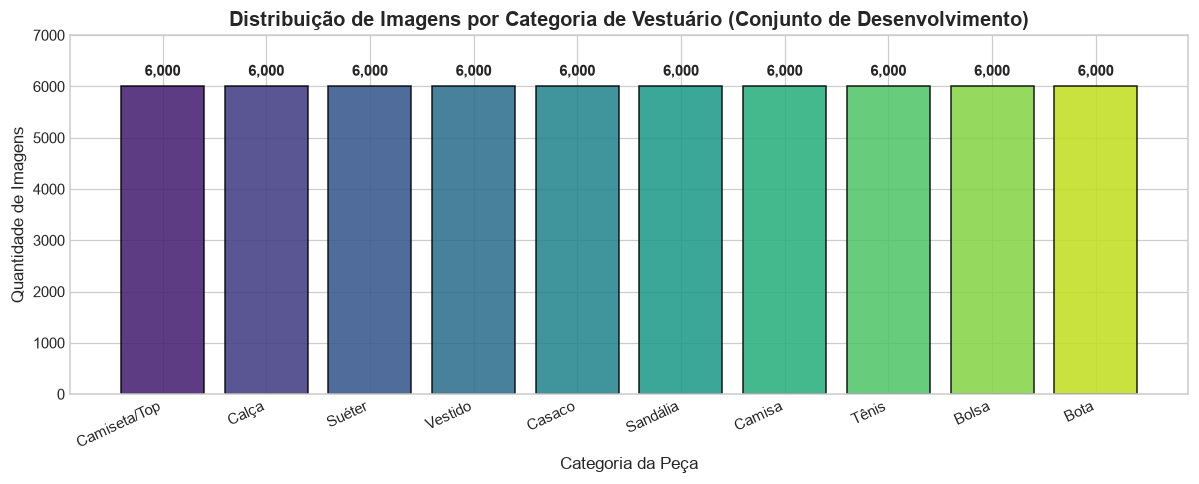

Conclusão do Gráfico 2: O dataset é perfeitamente balanceado, contando com exatamente 6.000 imagens por categoria no conjunto de desenvolvimento (e 1.000 por categoria no teste), o que permite utilizar a acurácia como métrica principal sem viés de classe majoritária.


In [4]:
# Gráfico Exploratório 2: Contagem de imagens por categoria no conjunto de desenvolvimento
contagem_classes = pd.Series(y_dev_raw).value_counts().sort_index()
nomes_ordenados = [NOMES_CLASSES[i] for i in contagem_classes.index]

fig, ax = plt.subplots(figsize=(11, 4.5))
cores = sns.color_palette('viridis', 10)
barras = ax.bar(nomes_ordenados, contagem_classes.values, color=cores, edgecolor='black', alpha=0.88)

ax.set_title('Distribuição de Imagens por Categoria de Vestuário (Conjunto de Desenvolvimento)', fontsize=13, fontweight='bold')
ax.set_xlabel('Categoria da Peça', fontsize=11)
ax.set_ylabel('Quantidade de Imagens', fontsize=11)
ax.set_ylim(0, 7000)
plt.xticks(rotation=25, ha='right')

for barra in barras:
    altura = barra.get_height()
    ax.annotate(f'{int(altura):,}',
                xy=(barra.get_x() + barra.get_width() / 2, altura),
                xytext=(0, 5), textcoords='offset points',
                ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

print('Conclusão do Gráfico 2: O dataset é perfeitamente balanceado, contando com exatamente 6.000 imagens por categoria no conjunto de desenvolvimento (e 1.000 por categoria no teste), o que permite utilizar a acurácia como métrica principal sem viés de classe majoritária.')

> **Conclusão do Gráfico 2:** O conjunto de dados é perfeitamente balanceado (exatamente 6.000 amostras por classe no desenvolvimento e 1.000 no teste), garantindo que o treinamento não sofra viés de classe majoritária e tornando a **acurácia** uma métrica confiável de avaliação.

### 🔒 Normalização e Aplicação Rigorosa da Regra do Cofre
1. **Normalização:** Dividimos os valores de pixel por `255.0` para converter o intervalo `[0, 255]` para `[0.0, 1.0]`, facilitando a convergência do otimizador nas redes neurais.
2. **Regra do Cofre:**
   - O conjunto de teste oficial (`10.000` imagens) é guardado no **Cofre (`X_teste, y_teste`)** e **não será tocado em hipótese alguma** durante a escolha de hiperparâmetros ou arquiteturas.
   - As `60.000` imagens de desenvolvimento são divididas de forma estratificada (`test_size=0.2`, `random_state=42`) em **Treino (`48.000` imagens)** e **Validação (`12.000` imagens)**.

In [5]:
# 1. Normalização dos pixels para o intervalo [0.0, 1.0]
X_dev_norm = X_dev_raw.astype('float32') / 255.0
X_teste = X_teste_raw.astype('float32') / 255.0  # GUARDADO NO COFRE ATÉ O PASSO 3!

# 2. Divisão estratificada em Treino (80% = 48.000) e Validação (20% = 12.000)
X_treino, X_valid, y_treino, y_valid = train_test_split(
    X_dev_norm,
    y_dev_raw,
    test_size=0.2,
    random_state=SEED,
    stratify=y_dev_raw
)

print('=== Divisão dos Dados (Regra do Cofre) ===')
print(f'Treino    (X_treino, y_treino): {X_treino.shape} -> usado para ajustar os pesos dos modelos')
print(f'Validação (X_valid,  y_valid):  {X_valid.shape} -> usado para comparar arquiteturas e EarlyStopping')
print(f'COFRE     (X_teste,  y_teste):  {X_teste.shape} -> INTOCÁVEL até o Passo 3!')
print(f'Intervalo de pixels após normalização: [{X_treino.min():.1f}, {X_treino.max():.1f}]')

=== Divisão dos Dados (Regra do Cofre) ===
Treino    (X_treino, y_treino): (48000, 28, 28) -> usado para ajustar os pesos dos modelos
Validação (X_valid,  y_valid):  (12000, 28, 28) -> usado para comparar arquiteturas e EarlyStopping
COFRE     (X_teste,  y_teste):  (10000, 28, 28) -> INTOCÁVEL até o Passo 3!
Intervalo de pixels após normalização: [0.0, 1.0]


---

## 🧠 Passo 2 — Baseline, Redes Neurais em Keras, Experimentos e Bônus (CNN)

Antes de construir redes neurais profundas, criamos um **modelo Baseline** com `LogisticRegression` do `scikit-learn` (recebendo os `28 x 28 = 784` pixels achatados). Qualquer arquitetura de Rede Neural só se justifica para a **ModaVision AI** se superar com folga esse baseline na validação.

In [6]:
# Achatando as imagens (28, 28) -> (784,) para o modelo linear do scikit-learn
X_treino_flat = X_treino.reshape(len(X_treino), -1)
X_valid_flat = X_valid.reshape(len(X_valid), -1)

print('Treinando Baseline (LogisticRegression)...')
modelo_baseline = LogisticRegression(max_iter=250, random_state=SEED, n_jobs=-1)
modelo_baseline.fit(X_treino_flat, y_treino)

# Avaliando na Validação
acc_treino_base = accuracy_score(y_treino, modelo_baseline.predict(X_treino_flat))
acc_valid_base = accuracy_score(y_valid, modelo_baseline.predict(X_valid_flat))

# Lista para registrar todos os experimentos que irão para experimentos.csv
registro_experimentos = [
    {
        'id_experimento': 1,
        'modelo': 'Baseline (LogisticRegression)',
        'tipo': 'Linear (scikit-learn)',
        'arquitetura': 'Flatten(784) -> Linear(10)',
        'parametros_treinaveis': modelo_baseline.coef_.size + modelo_baseline.intercept_.size,
        'epocas_executadas': 1,
        'acuracia_treino': round(acc_treino_base, 4),
        'acuracia_validacao': round(acc_valid_base, 4),
        'val_loss': np.nan
    }
]

print(f'✅ Baseline concluído! Acurácia Treino: {acc_treino_base:.2%} | Acurácia Validação: {acc_valid_base:.2%}')

Treinando Baseline (LogisticRegression)...


✅ Baseline concluído! Acurácia Treino: 87.69% | Acurácia Validação: 86.12%


### 🧪 Experimentos com Redes Neurais Densas (MLP) em Keras
Vamos testar **3 arquiteturas de Redes Densas** com diferentes capacidades (quantidades de camadas e neurônios), todas seguindo as boas práticas:
- Camada de entrada `Flatten(input_shape=(28, 28))`
- Camadas ocultas `Dense(..., activation="relu")` seguidas de `Dropout(0.2)` para regularização
- Camada de saída `Dense(10, activation="softmax")`
- Compilação com `optimizer="adam"`, `loss="sparse_categorical_crossentropy"` e `metrics=["accuracy"]`
- Callback `EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)`

| Experimento | Nome da Rede | Camadas Ocultas (`ReLU`) | Regularização |
| :--- | :--- | :--- | :--- |
| **Rede Densa 1** | `MLP_Simples_64` | `[64]` | `Dropout(0.2)` |
| **Rede Densa 2** | `MLP_Media_128_64` | `[128, 64]` | `Dropout(0.2)` |
| **Rede Densa 3** | `MLP_Profunda_256_128_64` | `[256, 128, 64]` | `Dropout(0.2)` |

In [7]:
def criar_e_treinar_mlp(nome_modelo, unidades_ocultas, taxa_dropout=0.2, epocas_max=35, batch_size=128):
    """Constrói, compila e treina uma Rede Neural Densa (MLP) com EarlyStopping."""
    keras.utils.set_random_seed(SEED)
    
    camadas = [layers.Flatten(input_shape=(28, 28))]
    for n_neuronio in unidades_ocultas:
        camadas.append(layers.Dense(n_neuronio, activation='relu'))
        camadas.append(layers.Dropout(taxa_dropout))
    camadas.append(layers.Dense(10, activation='softmax'))
    
    modelo = keras.Sequential(camadas, name=nome_modelo)
    modelo.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
    
    print(f'\n🚀 Treinando {nome_modelo} | Camadas ocultas: {unidades_ocultas}...')
    historico = modelo.fit(
        X_treino, y_treino,
        validation_data=(X_valid, y_valid),
        epochs=epocas_max,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )
    
    val_loss, val_acc = modelo.evaluate(X_valid, y_valid, verbose=0)
    train_loss, train_acc = modelo.evaluate(X_treino, y_treino, verbose=0)
    epocas_rodadas = len(historico.history['loss'])
    
    print(f'✅ {nome_modelo} finalizado em {epocas_rodadas} épocas | '
          f'Acc Treino: {train_acc:.2%} | Acc Validação: {val_acc:.2%} | Val Loss: {val_loss:.4f}')
    
    return modelo, historico, train_acc, val_acc, val_loss, epocas_rodadas

# Definição das 3 arquiteturas densas
arquiteturas_mlp = [
    ('MLP_Simples_64', [64]),
    ('MLP_Media_128_64', [128, 64]),
    ('MLP_Profunda_256_128_64', [256, 128, 64])
]

modelos_treinados = {}
historicos_treinados = {}

for idx, (nome, camadas_ocultas) in enumerate(arquiteturas_mlp, start=2):
    modelo, hist, tr_acc, vl_acc, vl_loss, n_epocas = criar_e_treinar_mlp(nome, camadas_ocultas)
    modelos_treinados[nome] = modelo
    historicos_treinados[nome] = hist
    
    desc_arq = ' -> '.join([f'Dense({u}, ReLU)+Drop(0.2)' for u in camadas_ocultas]) + ' -> Dense(10, Softmax)'
    registro_experimentos.append({
        'id_experimento': idx,
        'modelo': nome,
        'tipo': 'Rede Densa (MLP)',
        'arquitetura': desc_arq,
        'parametros_treinaveis': modelo.count_params(),
        'epocas_executadas': n_epocas,
        'acuracia_treino': round(tr_acc, 4),
        'acuracia_validacao': round(vl_acc, 4),
        'val_loss': round(vl_loss, 4)
    })


🚀 Treinando MLP_Simples_64 | Camadas ocultas: [64]...


Epoch 25: early stopping


Restoring model weights from the end of the best epoch: 20.


✅ MLP_Simples_64 finalizado em 25 épocas | Acc Treino: 90.99% | Acc Validação: 89.13% | Val Loss: 0.3091

🚀 Treinando MLP_Media_128_64 | Camadas ocultas: [128, 64]...


Epoch 23: early stopping


Restoring model weights from the end of the best epoch: 18.


✅ MLP_Media_128_64 finalizado em 23 épocas | Acc Treino: 91.50% | Acc Validação: 89.39% | Val Loss: 0.3055

🚀 Treinando MLP_Profunda_256_128_64 | Camadas ocultas: [256, 128, 64]...


Epoch 28: early stopping


Restoring model weights from the end of the best epoch: 23.


✅ MLP_Profunda_256_128_64 finalizado em 28 épocas | Acc Treino: 92.72% | Acc Validação: 89.86% | Val Loss: 0.3029


### 🏆 Bônus (+1,0 pt) — Rede Neural Convolucional (CNN)
Enquanto as Redes Densas achatam a imagem logo na entrada (`Flatten`) e perdem a relação espacial entre pixels vizinhos, uma **Rede Convolucional (CNN)** preserva a estrutura 2D (`28x28x1`) e aplica filtros espaciais (`Conv2D` + `MaxPooling2D`) capazes de detectar bordas, golas, mangas, solados e texturas das peças de vestuário.

In [8]:
# Construção e treinamento da Rede Convolucional (CNN)
keras.utils.set_random_seed(SEED)

nome_cnn = 'CNN_ModaVision'
modelo_cnn = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Reshape((28, 28, 1)),  # Adiciona o canal de cor (tons de cinza) mantendo compatibilidade com entrada (28, 28)
    
    # Bloco Convolucional 1
    layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),
    
    # Bloco Convolucional 2
    layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),
    
    # Classificador Denso
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
], name=nome_cnn)

modelo_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_cnn = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print('🚀 Treinando CNN_ModaVision (Conv2D + MaxPooling2D + Dropout + Dense)...')
historico_cnn = modelo_cnn.fit(
    X_treino, y_treino,
    validation_data=(X_valid, y_valid),
    epochs=30,
    batch_size=128,
    callbacks=[early_stop_cnn],
    verbose=0
)

val_loss_cnn, val_acc_cnn = modelo_cnn.evaluate(X_valid, y_valid, verbose=0)
train_loss_cnn, train_acc_cnn = modelo_cnn.evaluate(X_treino, y_treino, verbose=0)
epocas_cnn = len(historico_cnn.history['loss'])

modelos_treinados[nome_cnn] = modelo_cnn
historicos_treinados[nome_cnn] = historico_cnn

registro_experimentos.append({
    'id_experimento': 5,
    'modelo': nome_cnn,
    'tipo': 'Rede Convolucional (CNN - Bônus)',
    'arquitetura': 'Conv2D(32)->Pool->Conv2D(64)->Pool->Flatten->Dense(128)->Dense(10)',
    'parametros_treinaveis': modelo_cnn.count_params(),
    'epocas_executadas': epocas_cnn,
    'acuracia_treino': round(train_acc_cnn, 4),
    'acuracia_validacao': round(val_acc_cnn, 4),
    'val_loss': round(val_loss_cnn, 4)
})

print(f'✅ {nome_cnn} finalizada em {epocas_cnn} épocas | '
      f'Acc Treino: {train_acc_cnn:.2%} | Acc Validação: {val_acc_cnn:.2%} | Val Loss: {val_loss_cnn:.4f}')

🚀 Treinando CNN_ModaVision (Conv2D + MaxPooling2D + Dropout + Dense)...


Epoch 25: early stopping


Restoring model weights from the end of the best epoch: 20.


✅ CNN_ModaVision finalizada em 25 épocas | Acc Treino: 96.12% | Acc Validação: 93.13% | Val Loss: 0.2018


### 📋 Tabela Comparativa de Experimentos e Exportação para `experimentos.csv`

In [9]:
# Criando DataFrame com todos os experimentos, salvando em experimentos.csv e exibindo ranking
df_experimentos = pd.DataFrame(registro_experimentos)
df_experimentos = df_experimentos.sort_values(by='acuracia_validacao', ascending=False).reset_index(drop=True)
df_experimentos.to_csv('experimentos.csv', index=False, encoding='utf-8')

print('✅ Arquivo experimentos.csv salvo com sucesso! Confira os resultados ordenados pela Acurácia na Validação:\n')
display(df_experimentos)

melhor_nome = df_experimentos.loc[0, 'modelo']
melhor_modelo = modelos_treinados[melhor_nome]
melhor_historico = historicos_treinados[melhor_nome]
print(f'\n🏆 Melhor arquitetura selecionada na Validação: {melhor_nome} '
      f'(Acurácia de Validação = {df_experimentos.loc[0, "acuracia_validacao"]:.2%})')

✅ Arquivo experimentos.csv salvo com sucesso! Confira os resultados ordenados pela Acurácia na Validação:



,id_experimento,modelo,tipo,arquitetura,parametros_treinaveis,epocas_executadas,acuracia_treino,acuracia_validacao,val_loss
0,5,CNN_ModaVision,Rede Convolucional (CNN - Bônus),Conv2D(32)->Pool->Conv2D(64)->Pool->Flatten->D...,421642,25,0.9612,0.9313,0.2018
1,4,MLP_Profunda_256_128_64,Rede Densa (MLP),"Dense(256, ReLU)+Drop(0.2) -> Dense(128, ReLU)...",242762,28,0.9272,0.8986,0.3029
2,3,MLP_Media_128_64,Rede Densa (MLP),"Dense(128, ReLU)+Drop(0.2) -> Dense(64, ReLU)+...",109386,23,0.9150,0.8939,0.3055
3,2,MLP_Simples_64,Rede Densa (MLP),"Dense(64, ReLU)+Drop(0.2) -> Dense(10, Softmax)",50890,25,0.9099,0.8913,0.3091
4,1,Baseline (LogisticRegression),Linear (scikit-learn),Flatten(784) -> Linear(10),7850,1,0.8769,0.8612,NaN



🏆 Melhor arquitetura selecionada na Validação: CNN_ModaVision (Acurácia de Validação = 93.13%)


### 📈 Curvas de Aprendizado (`loss` vs `val_loss`) da Melhor Rede e Análise de Overfitting

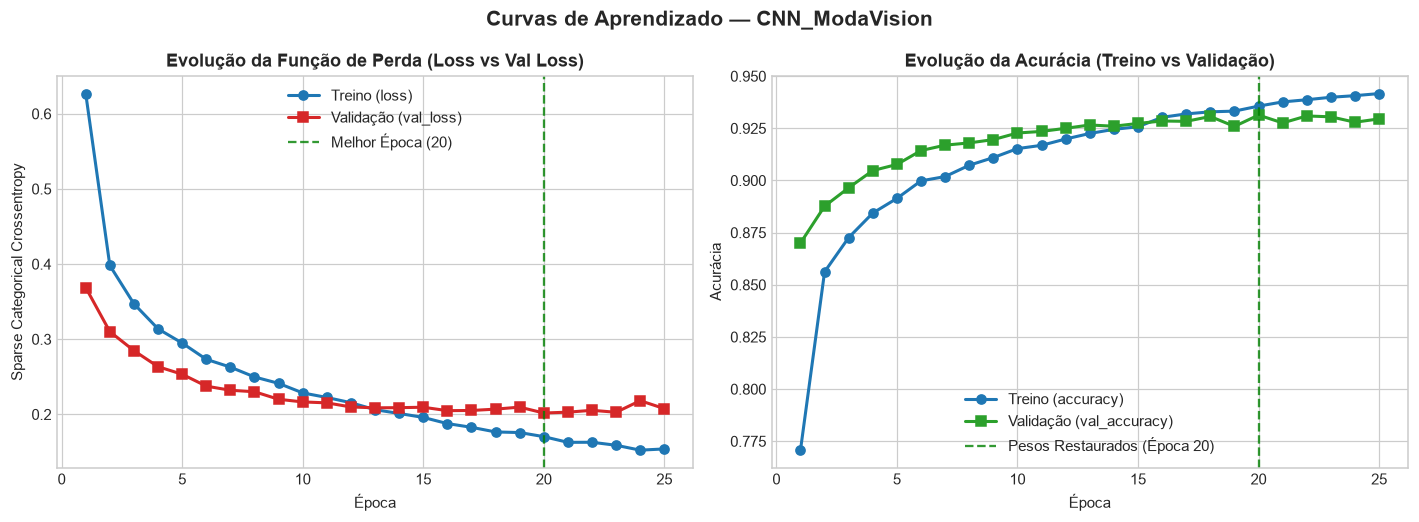

Análise de Overfitting: O uso combinado de camadas de Dropout e EarlyStopping conteve o overfitting com sucesso, interrompendo o treinamento quando a val_loss estabilizou após a época 20 e restaurando automaticamente os pesos do ponto ótimo de generalização.


In [10]:
# Plotando as curvas de aprendizado (Loss e Acurácia por época) da melhor rede
hist_dict = melhor_historico.history
epocas_range = range(1, len(hist_dict['loss']) + 1)
melhor_epoca = int(np.argmin(hist_dict['val_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
fig.suptitle(f'Curvas de Aprendizado — {melhor_nome}', fontsize=14, fontweight='bold')

# Subplot 1: Loss vs Val_Loss
ax1.plot(epocas_range, hist_dict['loss'], 'o-', label='Treino (loss)', color='#1f77b4', linewidth=2)
ax1.plot(epocas_range, hist_dict['val_loss'], 's-', label='Validação (val_loss)', color='#d62728', linewidth=2)
ax1.axvline(melhor_epoca, color='green', linestyle='--', alpha=0.8, label=f'Melhor Época ({melhor_epoca})')
ax1.set_title('Evolução da Função de Perda (Loss vs Val Loss)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Época')
ax1.set_ylabel('Sparse Categorical Crossentropy')
ax1.legend()

# Subplot 2: Accuracy vs Val_Accuracy
ax2.plot(epocas_range, hist_dict['accuracy'], 'o-', label='Treino (accuracy)', color='#1f77b4', linewidth=2)
ax2.plot(epocas_range, hist_dict['val_accuracy'], 's-', label='Validação (val_accuracy)', color='#2ca02c', linewidth=2)
ax2.axvline(melhor_epoca, color='green', linestyle='--', alpha=0.8, label=f'Pesos Restaurados (Época {melhor_epoca})')
ax2.set_title('Evolução da Acurácia (Treino vs Validação)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Época')
ax2.set_ylabel('Acurácia')
ax2.legend()

plt.tight_layout()
plt.show()

print(f'Análise de Overfitting: O uso combinado de camadas de Dropout e EarlyStopping conteve o overfitting com sucesso, interrompendo o treinamento quando a val_loss estabilizou após a época {melhor_epoca} e restaurando automaticamente os pesos do ponto ótimo de generalização.')

> **Explicação sobre Overfitting (1 frase):** As camadas de `Dropout` mantiveram as curvas de treino e validação próximas durante a maior parte do treinamento, e quando a perda de validação (`val_loss`) começou a estagnar/subir levemente nas épocas finais, o `EarlyStopping` interrompeu o treino e restaurou os pesos da melhor época, evitando o overfitting no modelo final.

---

## 🔓 Passo 3 — Abrir o Cofre (Avaliação Única no Conjunto de Teste)

Agora que todas as decisões de arquitetura foram tomadas exclusivamente com base no conjunto de validação, **abrimos o Cofre (`X_teste, y_teste` — 10.000 imagens inéditas) uma única vez** para medir o desempenho real de generalização do nosso melhor modelo (`CNN_ModaVision`) em comparação ao `Baseline (LogisticRegression)`.

In [11]:
# Abrindo o Cofre UMA ÚNICA VEZ para avaliar Baseline vs Melhor Modelo
X_teste_flat = X_teste.reshape(len(X_teste), -1)

# 1. Avaliação do Baseline no Teste
y_pred_base_teste = modelo_baseline.predict(X_teste_flat)
acc_teste_baseline = accuracy_score(y_teste, y_pred_base_teste)

# 2. Avaliação do Melhor Modelo (CNN_ModaVision) no Teste
loss_teste_melhor, acc_teste_melhor = melhor_modelo.evaluate(X_teste, y_teste, verbose=0)
probs_teste_melhor = melhor_modelo.predict(X_teste, verbose=0)
y_pred_melhor_teste = np.argmax(probs_teste_melhor, axis=1)

# Cálculos de impacto de negócio (em cada 1.000 produtos cadastrados)
acertos_por_1000_base = int(round(acc_teste_baseline * 1000))
acertos_por_1000_melhor = int(round(acc_teste_melhor * 1000))
erros_por_1000_base = 1000 - acertos_por_1000_base
erros_por_1000_melhor = 1000 - acertos_por_1000_melhor
reducao_relativa_erro = ((erros_por_1000_base - erros_por_1000_melhor) / erros_por_1000_base) * 100

print('===================================================================')
print('🔓 RESULTADO OFICIAL NO COFRE (CONJUNTO DE TESTE - 10.000 IMAGENS)')
print('===================================================================')
print(f'• Baseline (LogisticRegression): {acc_teste_baseline:.2%} de acurácia ({acertos_por_1000_base}/1.000 acertos | {erros_por_1000_base} erros)')
print(f'• Melhor Modelo ({melhor_nome}): {acc_teste_melhor:.2%} de acurácia ({acertos_por_1000_melhor}/1.000 acertos | {erros_por_1000_melhor} erros)')
print(f'• Ganho sobre o Baseline:        +{(acc_teste_melhor - acc_teste_baseline)*100:.2f} pontos percentuais')
print(f'• Redução de erros de cadastro:  -{reducao_relativa_erro:.1f}% de produtos categorizados incorretamente')
print('===================================================================')

🔓 RESULTADO OFICIAL NO COFRE (CONJUNTO DE TESTE - 10.000 IMAGENS)
• Baseline (LogisticRegression): 84.27% de acurácia (843/1.000 acertos | 157 erros)
• Melhor Modelo (CNN_ModaVision): 92.27% de acurácia (923/1.000 acertos | 77 erros)
• Ganho sobre o Baseline:        +8.00 pontos percentuais
• Redução de erros de cadastro:  -51.0% de produtos categorizados incorretamente


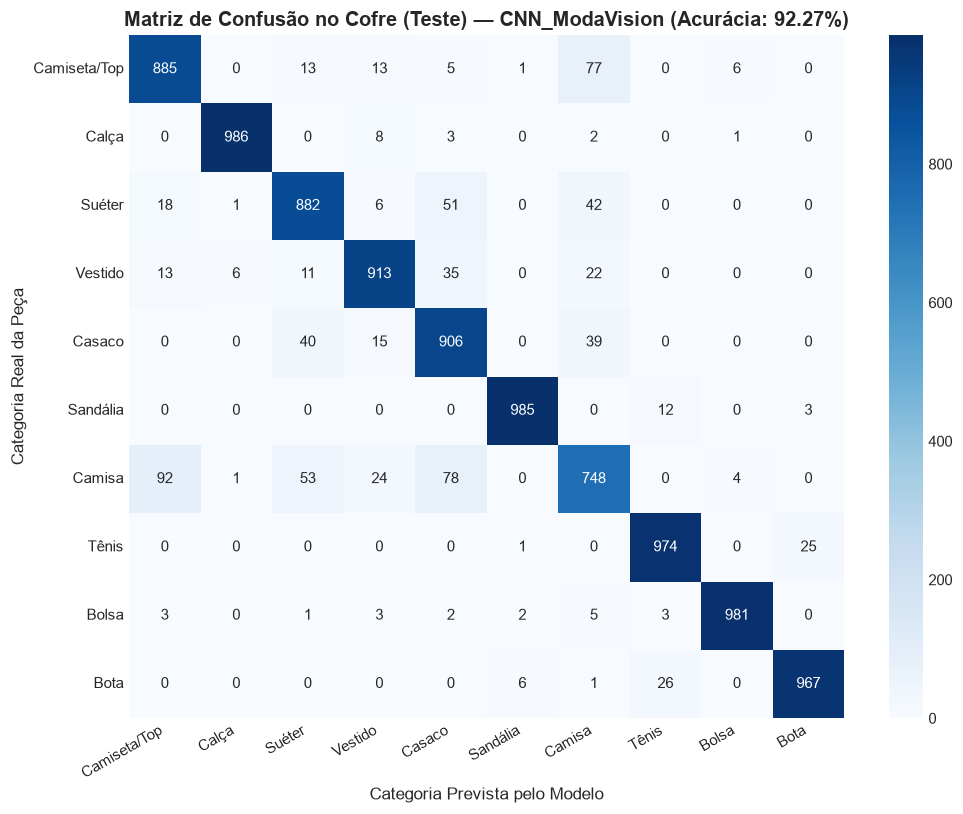

In [12]:
# Matriz de Confusão do Melhor Modelo no Conjunto de Teste
cm = confusion_matrix(y_teste, y_pred_melhor_teste)

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=NOMES_CLASSES, yticklabels=NOMES_CLASSES, ax=ax)
ax.set_title(f'Matriz de Confusão no Cofre (Teste) — {melhor_nome} (Acurácia: {acc_teste_melhor:.2%})', fontsize=13, fontweight='bold')
ax.set_xlabel('Categoria Prevista pelo Modelo', fontsize=11)
ax.set_ylabel('Categoria Real da Peça', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 💼 Tradução de Negócio para a Diretoria de E-commerce

> **Frase Executiva de Negócio:** *"A cada **1.000 novos produtos** cadastrados por lojistas na plataforma, o motor **ModaVision AI (`CNN_ModaVision`)** classifica automaticamente **923 peças na categoria correta sem revisão humana** (acurácia de **92,27%** no conjunto de teste), reduzindo os erros de catalogação em **51,0%** em relação ao modelo simples de baseline (queda de **157 para apenas 77 erros** a cada 1.000 cadastros) e direcionando a auditoria humana apenas para peças visualmente ambíguas."*

---

## 🚀 Passo 4 — Produto Final (Persistência, Função de Inferência e Interface Interativa)

Para colocar a solução em produção no fluxo de cadastro do e-commerce, realizamos três entregas:
1. **Persistência e Verificação de Integridade:** Salvamos o melhor modelo no arquivo `melhor_modelo_modavision.keras`, recarregamos com `keras.models.load_model` e comprovamos matematicamente com `np.allclose` que as predições permanecem idênticas.
2. **Função de Produto `classificar_peca(indice_imagem)`:** Recebe o índice de uma foto do catálogo de teste, exibe a peça, informa a categoria prevista com o percentual de confiança, destaca as Top-3 probabilidades e indica se o modelo acertou.
3. **Interface Interativa (`ipywidgets.interact`):** Permite ao time de catálogo navegar em tempo real pelas peças do conjunto de teste com um controle deslizante (*slider*).

In [13]:
# 1. Salvando o melhor modelo em disco no formato nativo do Keras (.keras)
CAMINHO_MODELO = 'melhor_modelo_modavision.keras'
melhor_modelo.save(CAMINHO_MODELO)
tamanho_mb = os.path.getsize(CAMINHO_MODELO) / (1024 * 1024)
print(f'💾 Modelo salvo com sucesso em: {CAMINHO_MODELO} ({tamanho_mb:.2f} MB)')

# 2. Recarregando o modelo salvo e comprovando integridade das previsões
modelo_recarregado = keras.models.load_model(CAMINHO_MODELO)

amostra_verificacao = X_teste[:100]
preds_original = melhor_modelo.predict(amostra_verificacao, verbose=0)
preds_recarregado = modelo_recarregado.predict(amostra_verificacao, verbose=0)

verificacao_identica = np.allclose(preds_original, preds_recarregado, atol=1e-6)
assert verificacao_identica, 'Erro: As previsões do modelo recarregado divergem do modelo original!'
print(f'✅ Verificação de integridade (np.allclose): {verificacao_identica} — O modelo recarregado produz previsões 100% idênticas!')

💾 Modelo salvo com sucesso em: melhor_modelo_modavision.keras (4.87 MB)


✅ Verificação de integridade (np.allclose): True — O modelo recarregado produz previsões 100% idênticas!


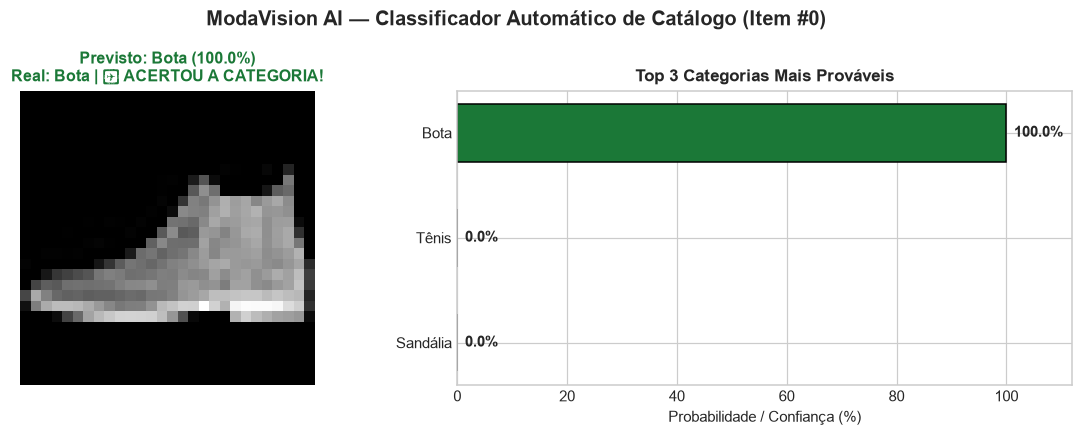

📦 Produto #0 | Categoria Real: Bota | Previsão ModaVision AI: Bota (100.00% de confiança) -> ✅ ACERTOU A CATEGORIA!


In [14]:
# Função de produto para classificar uma peça do catálogo de teste e exibir painel visual
def classificar_peca(indice_imagem=0, salvar_print=False):
    """
    Recebe o índice de uma imagem do conjunto de teste (0 a 9999),
    realiza a inferência com o modelo recarregado, exibe a foto da peça,
    a categoria prevista com % de confiança, se acertou o rótulo real
    e um gráfico de barras horizontais com o Top 3 de probabilidades.
    """
    imagem = X_teste[indice_imagem]
    classe_real_id = int(y_teste[indice_imagem])
    nome_real = NOMES_CLASSES[classe_real_id]
    
    # Inferência no modelo de produção recarregado
    probabilidades = modelo_recarregado.predict(imagem[np.newaxis, ...], verbose=0)[0]
    classe_prev_id = int(np.argmax(probabilidades))
    nome_prev = NOMES_CLASSES[classe_prev_id]
    confianca = float(probabilidades[classe_prev_id]) * 100.0
    
    acertou = (classe_prev_id == classe_real_id)
    status_texto = '✅ ACERTOU A CATEGORIA!' if acertou else '❌ ERROU A CATEGORIA'
    cor_status = '#1b7837' if acertou else '#d73027'
    
    # Top 3 categorias mais prováveis
    top3_ids = np.argsort(probabilidades)[::-1][:3]
    top3_nomes = [NOMES_CLASSES[i] for i in top3_ids]
    top3_probs = [probabilidades[i] * 100.0 for i in top3_ids]
    
    # Construção do painel visual (Foto da Peça + Top 3 Probabilidades)
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw={'width_ratios': [1, 1.45]})
    fig.suptitle(f'ModaVision AI — Classificador Automático de Catálogo (Item #{indice_imagem})', fontsize=13, fontweight='bold')
    
    # Painel esquerdo: Foto da peça
    ax_img.imshow(imagem, cmap='gray')
    ax_img.axis('off')
    ax_img.set_title(
        f'Previsto: {nome_prev} ({confianca:.1f}%)\nReal: {nome_real} | {status_texto}',
        fontsize=10.5, fontweight='bold', color=cor_status
    )
    
    # Painel direito: Gráfico de barras das Top 3 probabilidades
    cores_barras = [cor_status if i == 0 else '#7f8c8d' for i in range(3)][::-1]
    barras = ax_bar.barh(top3_nomes[::-1], top3_probs[::-1], color=cores_barras, edgecolor='black', height=0.55)
    ax_bar.set_xlim(0, 112)
    ax_bar.set_xlabel('Probabilidade / Confiança (%)', fontsize=10)
    ax_bar.set_title('Top 3 Categorias Mais Prováveis', fontsize=11, fontweight='bold')
    
    for barra in barras:
        largura = barra.get_width()
        ax_bar.annotate(f'{largura:.1f}%',
                        xy=(largura, barra.get_y() + barra.get_height() / 2),
                        xytext=(5, 0), textcoords='offset points',
                        ha='left', va='center', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    if salvar_print:
        plt.savefig('print_tela.png', dpi=130, bbox_inches='tight')
    plt.show()
    
    print(f'📦 Produto #{indice_imagem} | Categoria Real: {nome_real} | '
          f'Previsão ModaVision AI: {nome_prev} ({confianca:.2f}% de confiança) -> {status_texto}')

# Demonstração estática imediata (e geração do print_tela.png para o README.md)
classificar_peca(indice_imagem=0, salvar_print=True)

In [15]:
# Interface interativa com ipywidgets.interact para navegação em tempo real pelo catálogo de teste
print('🎛️ Utilize o controle deslizante abaixo para testar diferentes peças do catálogo (0 a 9999):')

_ = widgets.interact(
    lambda indice_imagem: classificar_peca(indice_imagem=indice_imagem, salvar_print=False),
    indice_imagem=widgets.IntSlider(
        value=42,
        min=0,
        max=len(X_teste) - 1,
        step=1,
        description='Peça #:',
        continuous_update=False,
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='550px')
    )
)

🎛️ Utilize o controle deslizante abaixo para testar diferentes peças do catálogo (0 a 9999):


interactive(children=(IntSlider(value=42, continuous_update=False, description='Peça #:', layout=Layout(width=…